# Независимые MLP для трёх выходов

Обучим три отдельные MLP для Weight, Waist и Pulse на одном разбиении Linnerud. Для каждой сети выберем лучшую эпоху и рассчитаем тестовую ошибку.


## Ход работы

Используем Linnerud и одно общее разбиение данных для трёх отдельных моделей. Масштабируем признаки и цели по train. Каждая MLP получает все три входных признака, но обучается предсказывать только одну величину: Weight, Waist или Pulse.

Для каждой сети отдельно создаём оптимизатор, сохраняем историю ошибок и выбираем лучшую эпоху по своей validation loss. После восстановления весов переводим прогнозы в исходные единицы и вычисляем тестовую MSE каждого выхода. На графиках сравниваем длительность обучения и расхождение train и validation для трёх задач.


### Импорты

Готовим PyTorch, Linnerud, нормализацию и графики. В отличие от предыдущей общей MLP, здесь будем обучать по одной сети на каждый выход.

In [1]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import copy

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


### Фиксируем начальное состояние

`torch.manual_seed` и `np.random.seed` упрощают воспроизведение. Но одинаковый seed сам по себе не устраняет различия между наборами данных и архитектурами.

In [2]:


# 1. Фиксируем случайность
torch.manual_seed(42)
np.random.seed(42)


### Три входа и три целевых величины

Загружаем Linnerud. Каждая независимая сеть увидит одинаковые три входных признака, но будет учиться предсказывать только один из Weight, Waist или Pulse.

In [3]:


# 2. Загружаем данные
data = load_linnerud()

X = data.data.astype(np.float32)
y = data.target.astype(np.float32)

names = ["Weight", "Waist", "Pulse"]

print("X:", X.shape)
print("y:", y.shape)


X: (20, 3)
y: (20, 3)


### Одинаковые разбиения для всех моделей

Создаём train, validation и test один раз, до обучения. Только при одинаковых разбиениях можно разумно сравнивать три независимых выхода с общей MLP.

In [4]:


# 3. Делим данные на Train / Validation / Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42
)


### Общая нормализация с обучением по train

Подгоняем `StandardScaler` только по тренировочным данным, затем применяем к остальным. Целевые величины нормализуем по столбцам, чтобы их масштабы не диктовали размер градиента.

In [5]:


# 4. Нормализуем данные
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

y_train = scaler_y.fit_transform(y_train)
y_val = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)


# Превращаем массивы в тензоры
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)


### Создаём архитектуру одной регрессионной сети

Каждая модель использует три входных признака и только один выход. Здесь «отдельная модель для выхода» не означает «отдельный слой»; у каждой сети собственные веса и оптимизатор.

In [6]:


# 5. Архитектура одной независимой MLP
def create_model():
    return nn.Sequential(
        nn.Linear(3, 16),
        nn.ReLU(),
        nn.Linear(16, 16),
        nn.ReLU(),
        nn.Linear(16, 1)
    )


### Функция обучения отдельной модели

Функция получает индекс целевого столбца, обучает отдельную MLP и выбирает собственную лучшую эпоху по validation. Поэтому Weight может остановиться раньше, чем Waist, без конфликта между ними.

In [7]:


# 6. Функция обучения одной MLP
def train_model(target_index):

    # Одинаковая начальная инициализация
    # для более честного сравнения выходов
    torch.manual_seed(42)

    model = create_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    train_history = []
    val_history = []

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())

    patience = 100
    epochs_without_improvement = 0

    # Выбираем один столбец целевых данных
    target_train = y_train[:, target_index:target_index + 1]
    target_val = y_val[:, target_index:target_index + 1]

    for epoch in range(1000):

        # Обучение
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train)
        train_loss = loss_fn(predictions, target_train)

        train_loss.backward()
        optimizer.step()

        # Проверка после обновления параметров
        model.eval()

        with torch.no_grad():
            train_loss_eval = loss_fn(
                model(X_train), target_train
            )

            val_loss = loss_fn(
                model(X_val), target_val
            )

        train_history.append(train_loss_eval.item())
        val_history.append(val_loss.item())

        # Early Stopping
        if val_loss.item() < best_val_loss:
            best_val_loss = val_loss.item()
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    # Возвращаем лучшие веса
    model.load_state_dict(best_weights)
    model.eval()

    return model, train_history, val_history, best_epoch, best_val_loss


### Три независимых обучения

In [8]:


# 7. Обучаем три независимые MLP
models = []
histories = []
predictions_scaled = np.zeros((len(X_test), 3), dtype=np.float32)

for i, name in enumerate(names):

    model, train_hist, val_hist, best_epoch, best_val = train_model(i)

    models.append(model)
    histories.append((train_hist, val_hist, best_epoch))

    with torch.no_grad():
        prediction = model(X_test).numpy().flatten()

    predictions_scaled[:, i] = prediction

    print(f"\n{name}")
    print(f"Лучшая эпоха: {best_epoch}")
    print(f"Лучший Validation MSE: {best_val:.6f}")



Weight
Лучшая эпоха: 18
Лучший Validation MSE: 0.209741



Waist
Лучшая эпоха: 460
Лучший Validation MSE: 0.262018

Pulse
Лучшая эпоха: 1
Лучший Validation MSE: 2.404187


### Возвращаем единицы измерения

Переводим прогнозы из стандартизованного масштаба обратно к исходным Weight, Waist, Pulse и рассчитываем MSE по каждому столбцу.

In [9]:


# 8. Возвращаем предсказания в исходный масштаб
predictions_original = scaler_y.inverse_transform(
    predictions_scaled
)

print("\nTEST RESULTS")

for i, name in enumerate(names):
    mse = np.mean(
        (predictions_original[:, i] - y_test[:, i]) ** 2
    )
    print(f"{name}: MSE = {mse:.4f}")

print("\nПервое предсказание:")
print("Предсказано:", np.round(predictions_original[0], 2))
print("Правильный ответ:", y_test[0])



TEST RESULTS
Weight: MSE = 284.4683
Waist: MSE = 4.6872
Pulse: MSE = 21.3758

Первое предсказание:
Предсказано: [180.52  32.56  55.93]
Правильный ответ: [157.  32.  52.]


### Графики трёх независимых тренировок

У каждого выхода собственные графики train/validation и своя лучшая эпоха. Важно сравнивать не только качество на train, но и устойчивость на validation и test.

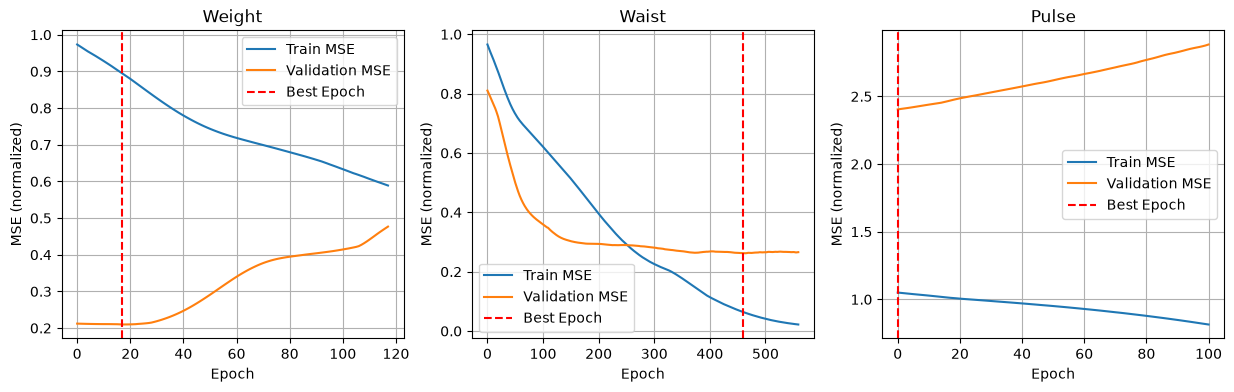

In [10]:


# 9. Строим графики
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, name in enumerate(names):

    train_hist, val_hist, best_epoch = histories[i]

    axes[i].plot(train_hist, label="Train MSE")
    axes[i].plot(val_hist, label="Validation MSE")

    axes[i].axvline(
        best_epoch - 1,
        color="red",
        linestyle="--",
        label="Best Epoch"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (normalized)")
    axes[i].grid(True)
    axes[i].legend()


### Выводим итоговые кривые

Отображаем результаты трёх обучений. Улучшение отдельного выхода не гарантирует, что набор независимых моделей превзойдёт общую сеть на всех целях.

In [11]:

plt.suptitle("Independent MLP Training")
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

## Выводы

У каждой сети свои веса и лучшая эпоха. Отдельное обучение позволяет настроить каждый выход, но само по себе не гарантирует меньшую тестовую ошибку. В test всего четыре объекта, поэтому оценки чувствительны к разбиению.


## Полный код


X: (20, 3)
y: (20, 3)

Weight
Лучшая эпоха: 18
Лучший Validation MSE: 0.209741



Waist
Лучшая эпоха: 460
Лучший Validation MSE: 0.262018

Pulse
Лучшая эпоха: 1
Лучший Validation MSE: 2.404187

TEST RESULTS
Weight: MSE = 284.4683
Waist: MSE = 4.6872
Pulse: MSE = 21.3758

Первое предсказание:
Предсказано: [180.52  32.56  55.93]
Правильный ответ: [157.  32.  52.]


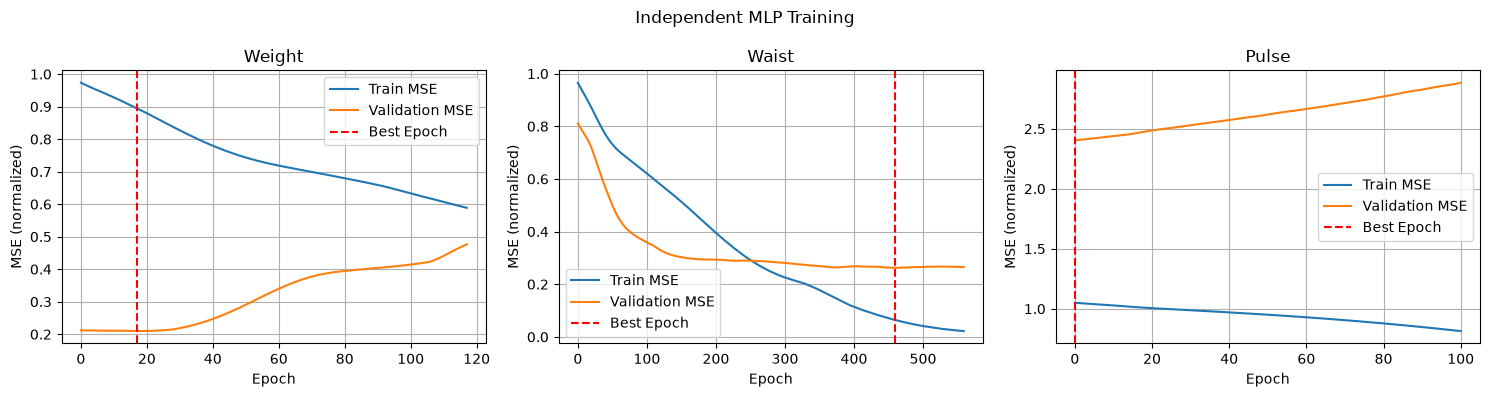

In [12]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import copy

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# 1. Фиксируем случайность
torch.manual_seed(42)
np.random.seed(42)


# 2. Загружаем данные
data = load_linnerud()

X = data.data.astype(np.float32)
y = data.target.astype(np.float32)

names = ["Weight", "Waist", "Pulse"]

print("X:", X.shape)
print("y:", y.shape)


# 3. Делим данные на Train / Validation / Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42
)


# 4. Нормализуем данные
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

y_train = scaler_y.fit_transform(y_train)
y_val = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)


# Превращаем массивы в тензоры
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)


# 5. Архитектура одной независимой MLP
def create_model():
    return nn.Sequential(
        nn.Linear(3, 16),
        nn.ReLU(),
        nn.Linear(16, 16),
        nn.ReLU(),
        nn.Linear(16, 1)
    )


# 6. Функция обучения одной MLP
def train_model(target_index):

    # Одинаковая начальная инициализация
    # для более честного сравнения выходов
    torch.manual_seed(42)

    model = create_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.01
    )

    loss_fn = nn.MSELoss()

    train_history = []
    val_history = []

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())

    patience = 100
    epochs_without_improvement = 0

    # Выбираем один столбец целевых данных
    target_train = y_train[:, target_index:target_index + 1]
    target_val = y_val[:, target_index:target_index + 1]

    for epoch in range(1000):

        # Обучение
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train)
        train_loss = loss_fn(predictions, target_train)

        train_loss.backward()
        optimizer.step()

        # Проверка после обновления параметров
        model.eval()

        with torch.no_grad():
            train_loss_eval = loss_fn(
                model(X_train), target_train
            )

            val_loss = loss_fn(
                model(X_val), target_val
            )

        train_history.append(train_loss_eval.item())
        val_history.append(val_loss.item())

        # Early Stopping
        if val_loss.item() < best_val_loss:
            best_val_loss = val_loss.item()
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    # Возвращаем лучшие веса
    model.load_state_dict(best_weights)
    model.eval()

    return model, train_history, val_history, best_epoch, best_val_loss


# 7. Обучаем три независимые MLP
models = []
histories = []
predictions_scaled = np.zeros((len(X_test), 3), dtype=np.float32)

for i, name in enumerate(names):

    model, train_hist, val_hist, best_epoch, best_val = train_model(i)

    models.append(model)
    histories.append((train_hist, val_hist, best_epoch))

    with torch.no_grad():
        prediction = model(X_test).numpy().flatten()

    predictions_scaled[:, i] = prediction

    print(f"\n{name}")
    print(f"Лучшая эпоха: {best_epoch}")
    print(f"Лучший Validation MSE: {best_val:.6f}")


# 8. Возвращаем предсказания в исходный масштаб
predictions_original = scaler_y.inverse_transform(
    predictions_scaled
)

print("\nTEST RESULTS")

for i, name in enumerate(names):
    mse = np.mean(
        (predictions_original[:, i] - y_test[:, i]) ** 2
    )
    print(f"{name}: MSE = {mse:.4f}")

print("\nПервое предсказание:")
print("Предсказано:", np.round(predictions_original[0], 2))
print("Правильный ответ:", y_test[0])


# 9. Строим графики
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, name in enumerate(names):

    train_hist, val_hist, best_epoch = histories[i]

    axes[i].plot(train_hist, label="Train MSE")
    axes[i].plot(val_hist, label="Validation MSE")

    axes[i].axvline(
        best_epoch - 1,
        color="red",
        linestyle="--",
        label="Best Epoch"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (normalized)")
    axes[i].grid(True)
    axes[i].legend()

plt.suptitle("Independent MLP Training")
plt.tight_layout()
plt.show()
